In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import KFold

In [2]:
nfl = pd.read_csv('NFL Play by Play 2009-2016 (v3).csv', low_memory = False)

# Question 1
## Can we predict what play type the offense will call? Run or Pass? 

In [3]:
playPrediction = nfl[['PlayType', 'down', 'ydstogo', 'yrdline100', 'GoalToGo', 
                      'qtr', 'TimeSecs', 'ScoreDiff', 'posteam_timeouts_pre', 'Season']]
playPrediction = (playPrediction
    .query('PlayType in ["Pass", "Run"]')
    .query("qtr <= 4")
    .assign(PlayType = lambda df: np.where(df['PlayType'] == 'Pass', 1, 0))
    .rename(columns = {'down' : 'Down', 'ydstogo' : 'YdsToGo', 'yrdline100' : 'YrdLine', 
                       'qtr' : 'Qtr', 'TimeSecs' : 'Time', 'posteam_timeouts_pre' : 'OffTimeouts_Pre'})
    .dropna()
)
playPrediction

,PlayType,Down,YdsToGo,YrdLine,GoalToGo,Qtr,Time,ScoreDiff,OffTimeouts_Pre,Season
1,1,1.0,10,58.0,0.0,1,3593.0,0.0,3,2009
2,0,2.0,5,53.0,0.0,1,3556.0,0.0,3,2009
3,1,3.0,8,56.0,0.0,1,3515.0,0.0,3,2009
5,0,1.0,10,98.0,0.0,1,3496.0,0.0,3,2009
6,1,2.0,10,98.0,0.0,1,3460.0,0.0,3,2009
...,...,...,...,...,...,...,...,...,...,...
362432,1,1.0,10,21.0,0.0,4,117.0,-14.0,1,2016
362433,1,2.0,10,21.0,0.0,4,113.0,-14.0,1,2016
362434,1,3.0,4,15.0,0.0,4,95.0,-14.0,1,2016
362435,0,1.0,10,80.0,0.0,4,90.0,14.0,2,2016


### Data Exploration

In [4]:
playPrediction.describe()

,PlayType,Down,YdsToGo,YrdLine,GoalToGo,Qtr,Time,ScoreDiff,OffTimeouts_Pre,Season
count,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000,246961.000000
mean,0.569057,1.785800,8.612615,52.522406,0.058236,2.535506,1754.894004,-1.364240,2.569932,2012.513255
std,0.495209,0.814436,3.925477,24.733987,0.234189,1.116829,1045.587477,10.768988,0.739483,2.286911
min,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,-59.000000,0.000000,2009.000000
25%,0.000000,1.000000,6.000000,34.000000,0.000000,2.000000,854.000000,-7.000000,2.000000,2011.000000
50%,1.000000,2.000000,10.000000,56.000000,0.000000,3.000000,1800.000000,0.000000,3.000000,2013.000000
75%,1.000000,2.000000,10.000000,73.000000,0.000000,4.000000,2651.000000,4.000000,3.000000,2015.000000
max,1.000000,4.000000,50.000000,99.000000,1.000000,4.000000,3600.000000,59.000000,3.000000,2016.000000


In [5]:
playPrediction["PlayType"].value_counts()
# Run = 0, Pass = 1

PlayType
1    140535
0    106426
Name: count, dtype: int64

<Axes: xlabel='YdsToGo', ylabel='Count'>

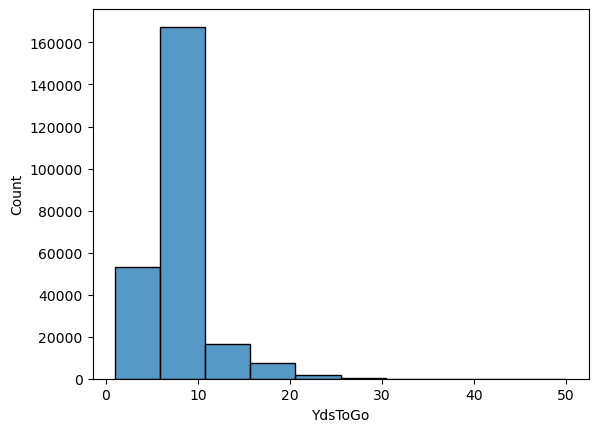

In [6]:
sns.histplot(playPrediction['YdsToGo'], bins = 10)

<Axes: xlabel='Time', ylabel='Count'>

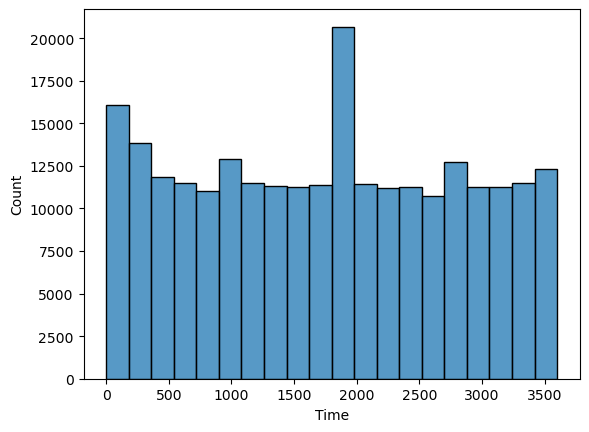

In [7]:
sns.histplot(playPrediction['Time'], bins = 20)

<Axes: xlabel='ScoreDiff', ylabel='Count'>

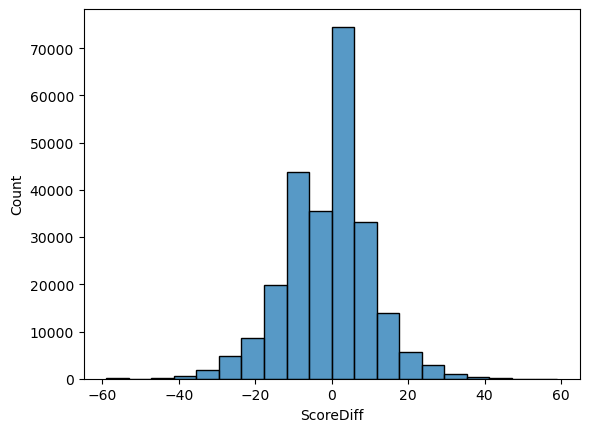

In [8]:
sns.histplot(playPrediction['ScoreDiff'], bins = 20)

<Axes: xlabel='PlayType', ylabel='YdsToGo'>

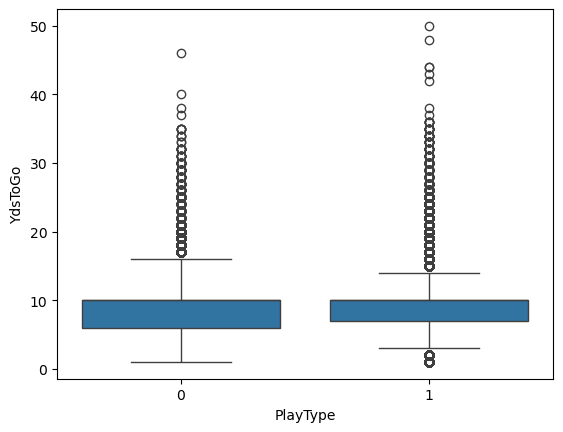

In [9]:
sns.boxplot(x = 'PlayType', y = 'YdsToGo', data = playPrediction)
# Run = 0, Pass = 1

In [10]:
playPrediction.corr()

,PlayType,Down,YdsToGo,YrdLine,GoalToGo,Qtr,Time,ScoreDiff,OffTimeouts_Pre,Season
PlayType,1.000000,0.210180,0.090961,0.024324,-0.037191,0.032688,-0.051757,-0.162556,-0.092135,0.021960
Down,0.210180,1.000000,-0.322114,-0.074809,-0.003978,0.029883,-0.039005,-0.000316,-0.041942,-0.007112
YdsToGo,0.090961,-0.322114,1.000000,0.236021,-0.210691,0.003903,-0.002345,-0.014881,-0.000495,0.007101
YrdLine,0.024324,-0.074809,0.236021,1.000000,-0.474900,-0.044502,0.067664,-0.024560,0.060649,0.008953
GoalToGo,-0.037191,-0.003978,-0.210691,-0.474900,1.000000,0.017840,-0.027122,0.002530,-0.036868,0.000570
Qtr,0.032688,0.029883,0.003903,-0.044502,0.017840,1.000000,-0.966168,-0.047533,-0.213112,0.000470
Time,-0.051757,-0.039005,-0.002345,0.067664,-0.027122,-0.966168,1.000000,0.057320,0.295041,-0.000955
ScoreDiff,-0.162556,-0.000316,-0.014881,-0.024560,0.002530,-0.047533,0.057320,1.000000,0.029142,-0.012496
OffTimeouts_Pre,-0.092135,-0.041942,-0.000495,0.060649,-0.036868,-0.213112,0.295041,0.029142,1.000000,0.025407
Season,0.021960,-0.007112,0.007101,0.008953,0.000570,0.000470,-0.000955,-0.012496,0.025407,1.000000


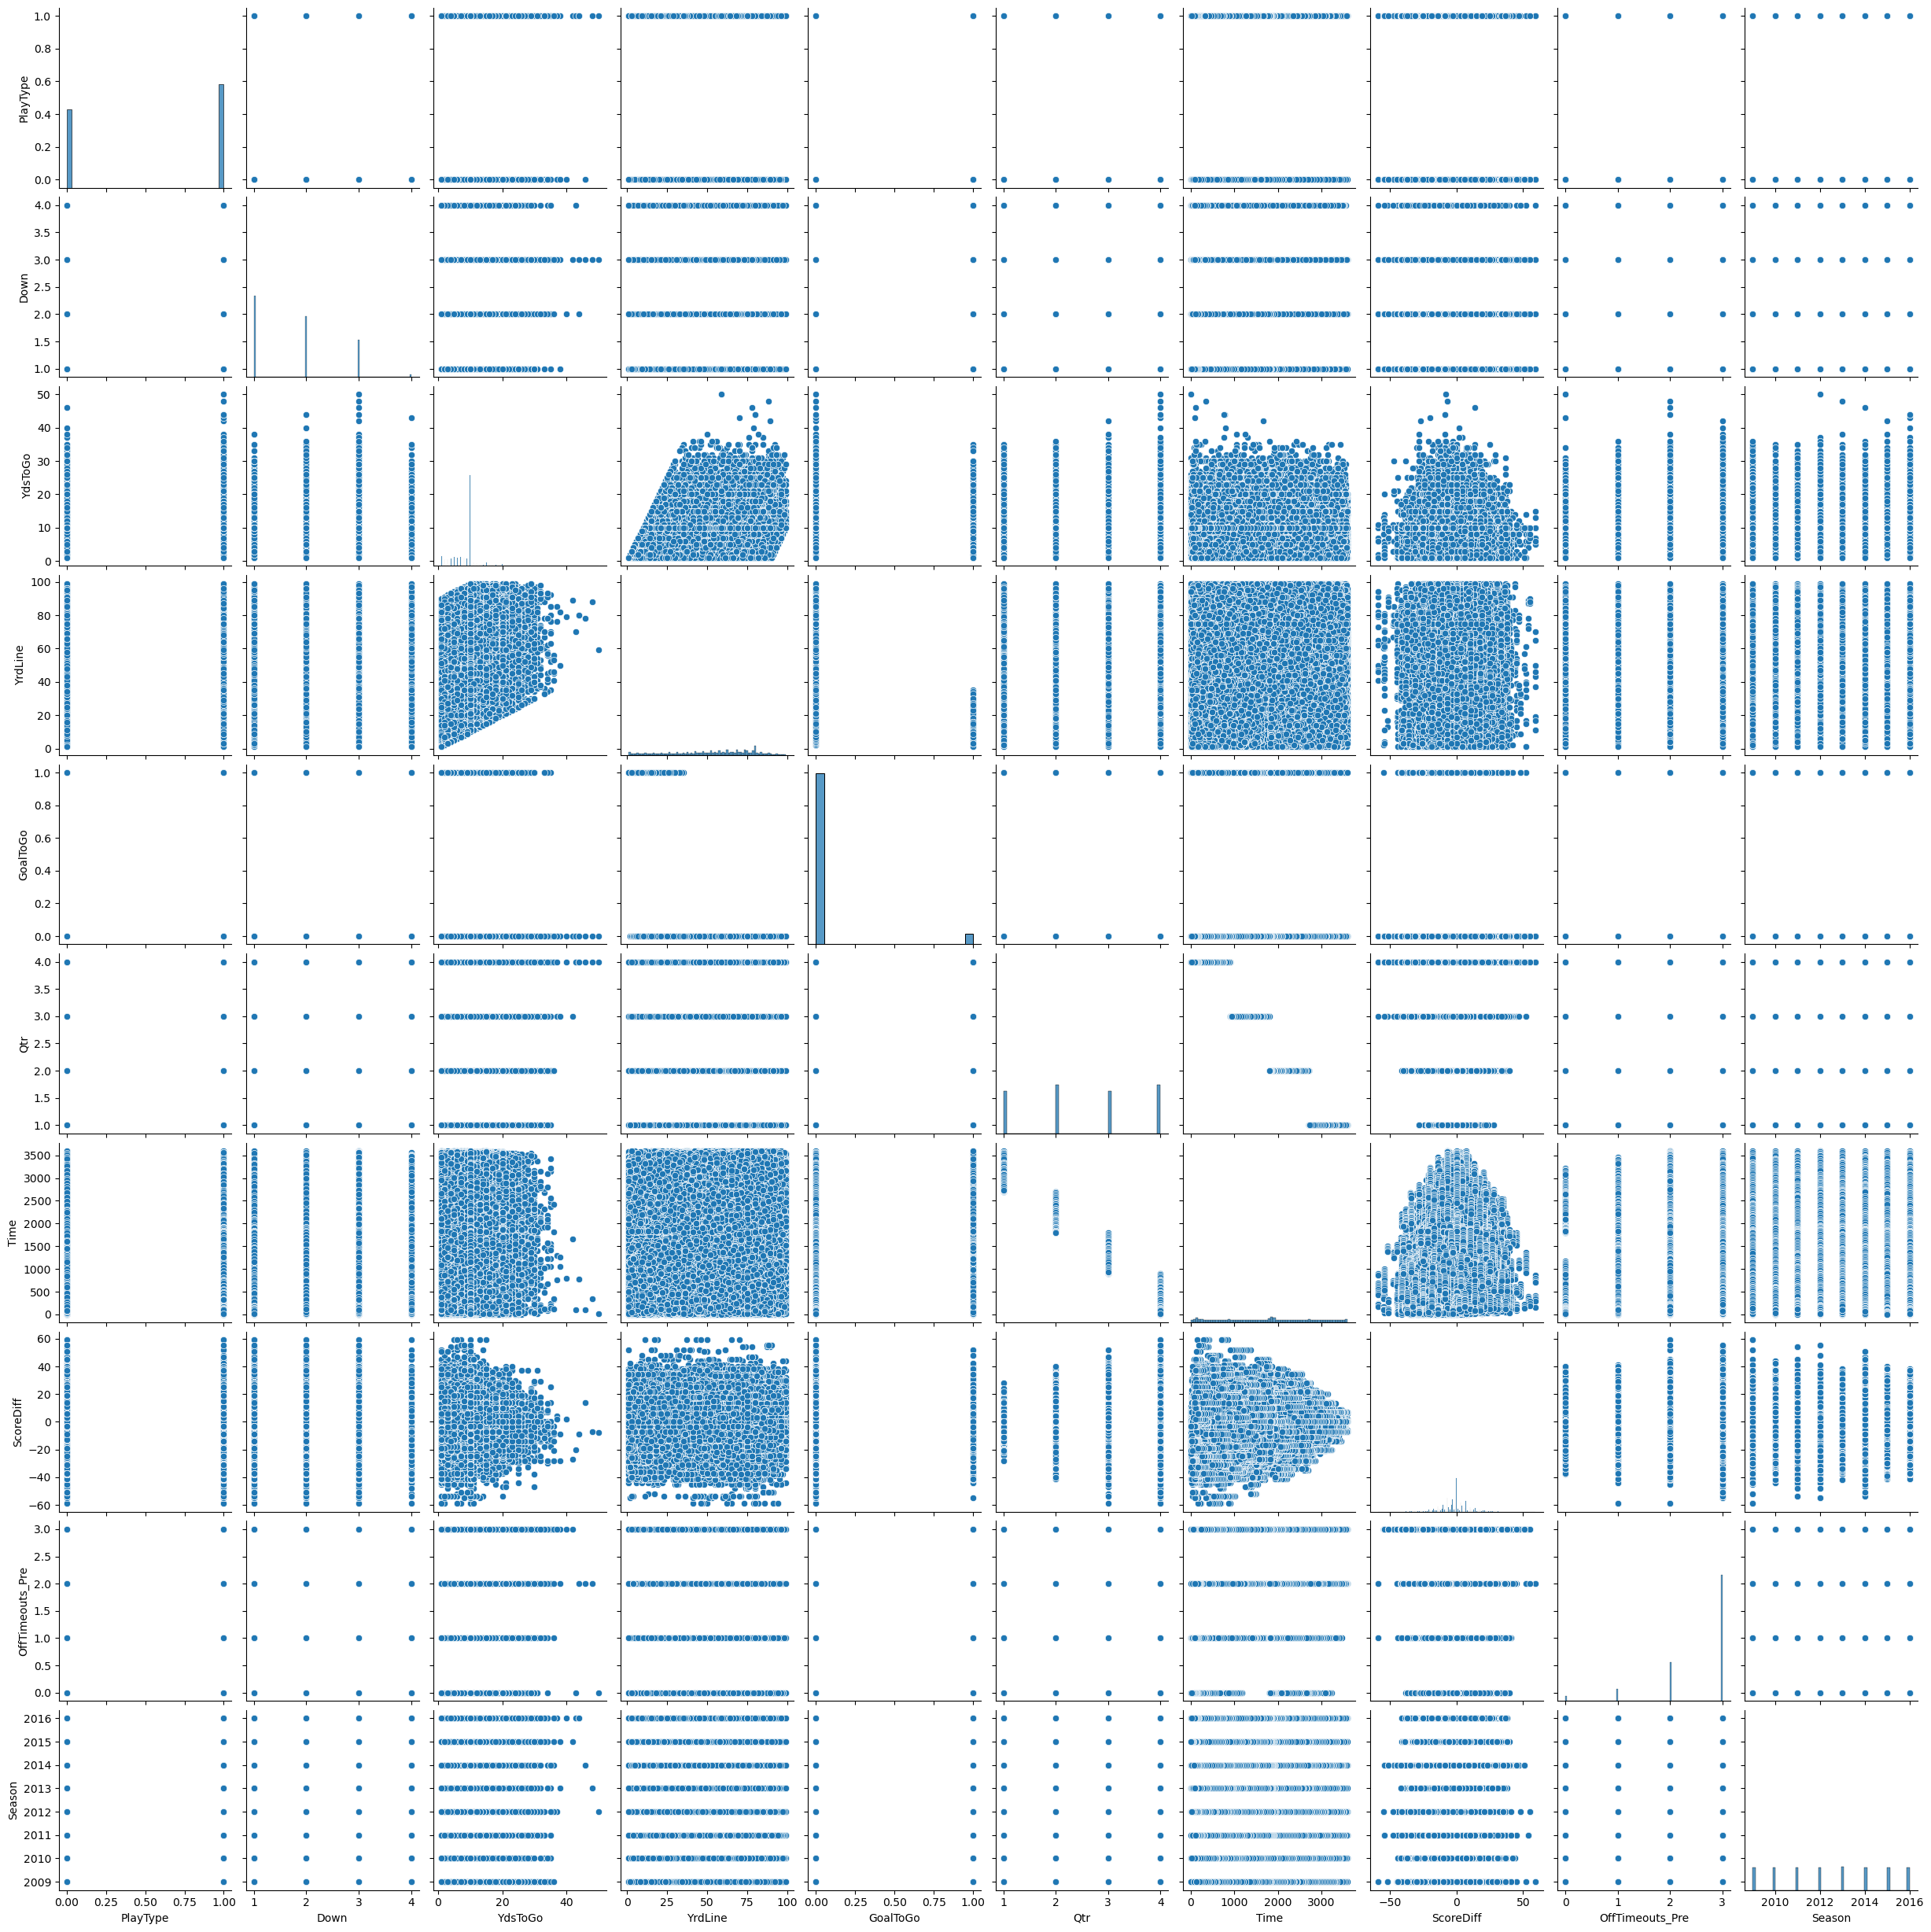

In [11]:
sns.pairplot(playPrediction)

### Logistic Regression

In [12]:
Y = playPrediction['PlayType']
X = playPrediction[['Down', 'YdsToGo', 'YrdLine', 'GoalToGo', 'Qtr', 'Time', 'ScoreDiff', 'OffTimeouts_Pre', 'Season']]
X_train, X_test, Y_train, Y_test = \
    train_test_split(X, Y, test_size = 0.30, random_state = 123)
fit_lm = LogisticRegression(max_iter = 1000).fit(X_train, Y_train)
pred_lm = fit_lm.predict(X_test)
cnf_matrix = metrics.confusion_matrix(Y_test, pred_lm, labels = [0, 1])
cnf_matrix

array([[17559, 14378],
       [11220, 30932]])

In [13]:
accuracy = (17559 + 30932) / (17559 + 14378 + 11220 + 30932)
print(accuracy * 100)

65.44966189312854


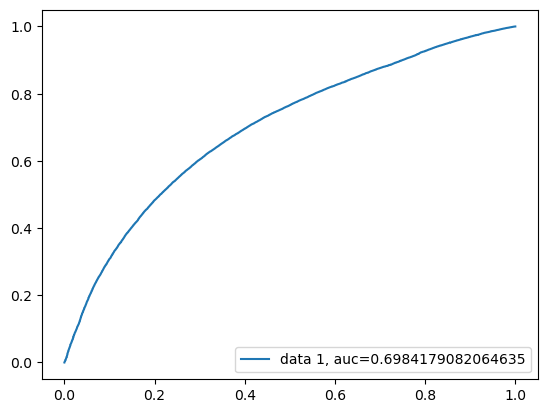

In [14]:
y_pred_proba = fit_lm.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(Y_test,  y_pred_proba)
auc = metrics.roc_auc_score(Y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

### Random Forests

In [ ]:
rf = RandomForestClassifier(random_state = 123)
rf_grid = {'n_estimators' : np.arange(10, 210, 10), 'max_features' : np.arange(0.2, 1.2, 0.2)}
grid = GridSearchCV(estimator = rf,
                    param_grid = rf_grid,
                    cv = KFold(n_splits = 10, shuffle = True, random_state = 123),
                    scoring = 'accuracy')
grid.fit(X, Y)

# Question 2
## What factors contribute most to successful offensive plays?